In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.stats import chi2_contingency
import scipy.stats as stats
from scipy.stats.contingency import association
%matplotlib inline
pd.set_option('display.max_columns', None)

In [2]:
# Specify the path to the zipped file and the CSV file within it
zip_file_path = 'archive (1).zip'
csv_file_name = 'yourfile.csv'  
# Read the CSV directly from the zip file
df = pd.read_csv(zip_file_path, compression='zip')

# Part 1: Analyzing Best-Seller Trends Across Product Categories

#### Objective: Understand the relationship between product categories and their best-seller status.

- Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

- Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.

- Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.


In [43]:
df = df.sample(5000)

In [44]:
# General Selection
cat = df.select_dtypes(exclude="number")
num = df.select_dtypes(include="number")

# Being specific
cat_from_num = num.loc[:, num.nunique() < 20] 
cat = pd.concat([cat, cat_from_num], axis=1)
num = num.drop(columns=cat_from_num.columns)

In [45]:
crosstab_result = pd.crosstab(df.category, df.isBestSeller)

In [46]:
crosstab_result

isBestSeller,False,True
category,,
3D Printers,1,0
3D Printing & Scanning,11,0
Abrasive & Finishing Products,1,0
Action Cameras,7,0
Agricultural Equipment & Supplies,11,0
...,...,...
Vacuums & Floorcare,9,0
Wearable Technology,14,0
Wind Instruments,1,0


In [47]:
crosstab_result['proportion_best_sellers'] = (crosstab_result[True] / (crosstab_result[False] + crosstab_result[True]) * 100)
crosstab = crosstab_result.sort_values(by='proportion_best_sellers', ascending=False)

In [48]:
crosstab

isBestSeller,False,True,proportion_best_sellers
category,,,
String Instruments,0,1,100.000000
Building Supplies,12,1,7.692308
Mobile Phones & Communication,17,1,5.555556
Printers & Accessories,17,1,5.555556
Customers' Most Loved,19,1,5.000000
...,...,...,...
Gifts for Her,2,0,0.000000
Girls,19,0,0.000000
Golf Shoes,10,0,0.000000


In [49]:
# Chi-square test for 'MSZoning' and 'SaleCondition'
chi2_stats = chi2_stats, chi2_pvalue, _, _ = chi2_contingency(crosstab_result)

In [50]:
p_val = chi2_pvalue

In [51]:
crosstab_counts = crosstab_result.iloc[:, :2] 

In [52]:
# Computing the association between variables in 'crosstab_result' using the "cramer" method
cramers_v = association(crosstab_counts, method='cramer')

In [53]:
print("Chi-square Test Statistic:", chi2_stats) # variables are associated
print("P-value:", p_val) # reject the null hypothesis of independence
print("Cramér's V:", cramers_v) # are not entirely independent, the strength of the relationship is modest

Chi-square Test Statistic: 4112.9715427328465
P-value: 0.0
Cramér's V: 0.39198849576298467


In [54]:
top5 = crosstab_result.head(5)

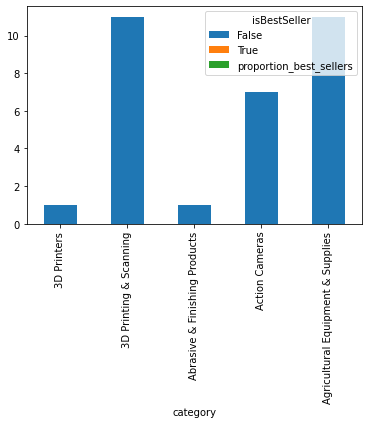

In [55]:
top5.plot(kind='bar', stacked=True)
plt.show()

# Part 2: Exploring Product Prices and Ratings Across Categories and Brands

#### Objective: Investigate how different product categories influence product prices.

- Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

-  Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.

- Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.

- Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [56]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    return outliers

In [61]:
data_series = df['price']  # replace 'ColumnName' with your specific column
outliers = tukeys_test_outliers(data_series)
print(outliers)

759941      307.49
1781189     147.61
315011      523.59
1729763     133.53
2488        109.95
            ...   
761467     1293.32
2084016     122.38
1279811     552.99
2391812     130.99
775353      113.39
Name: price, Length: 698, dtype: float64


In [62]:
df['price_no_outliers'] = tukeys_test_outliers(df['price'])

In [63]:
top_20_categories = df['category'].value_counts().nlargest(20).index
df_top_20 = df[df['category'].isin(top_20_categories)]

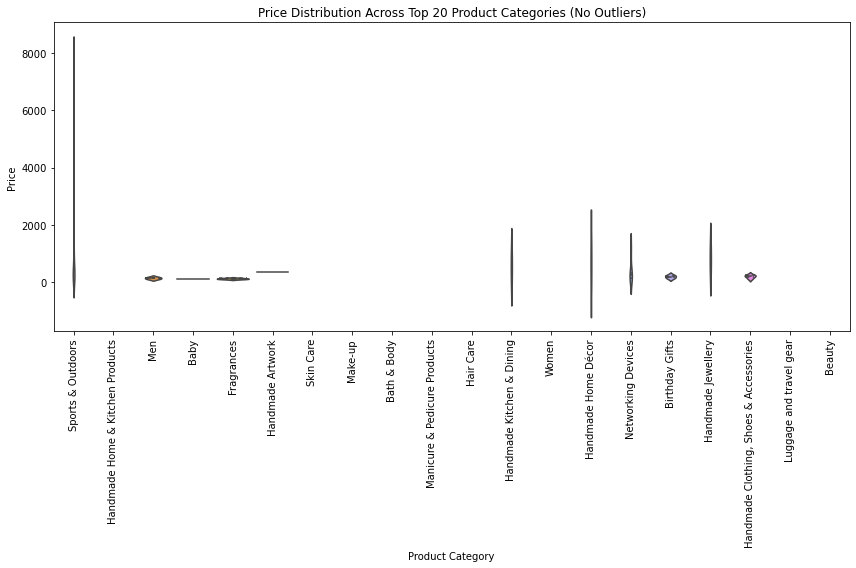

In [64]:
plt.figure(figsize=(12, 8))
sns.violinplot(data=df_top_20, x='category', y='price_no_outliers', inner='quartile')
plt.xticks(rotation=90)
plt.title("Price Distribution Across Top 20 Product Categories (No Outliers)")
plt.xlabel("Product Category")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

# Part 3: Investigating the Interplay Between Product Prices and Ratings
#### Objective: Analyze how product ratings (stars) correlate with product prices.

- Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?

- Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

In [65]:
crosstab_result = pd.crosstab(df['price'], df['stars'])

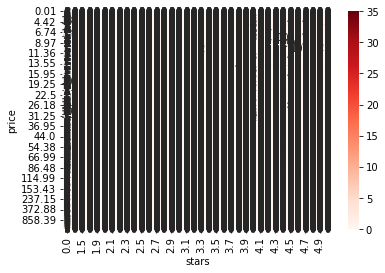

In [75]:
sns.heatmap(crosstab_result, annot=True, cmap="Reds", fmt="d")
plt.show()

In [70]:
correlation_coefficient = df['price'].corr(df['stars'])

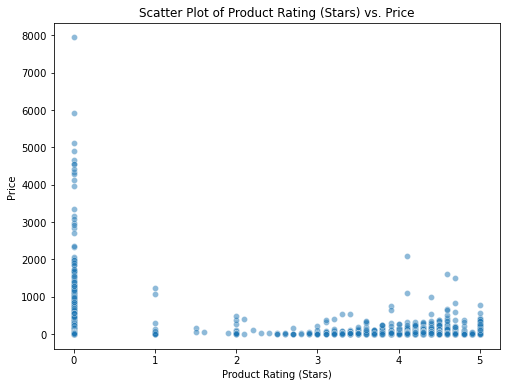

In [72]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='stars', y='price', alpha=0.5)
plt.title("Scatter Plot of Product Rating (Stars) vs. Price")
plt.xlabel("Product Rating (Stars)")
plt.ylabel("Price")
plt.show()

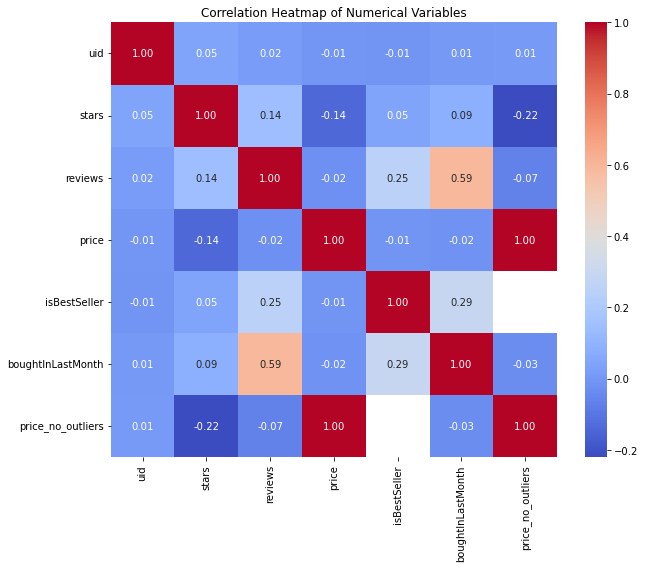

In [73]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

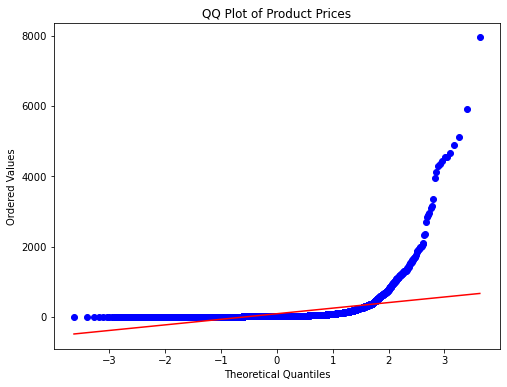

In [74]:
plt.figure(figsize=(8, 6))
stats.probplot(df['price'], dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Ordered Values")
plt.show()